# VAR and IRF Analysis (1987-2003)

This notebook builds a Vector Autoregression (VAR) model to analyze the impulse response of Case-Shiller Home Price Indexes to a shock in the Federal Funds Rate (FFR).

**Time Period:** 1987-01-01 to 2003-07-01 (Pre-bubble peak)

**Variables:**
*   `unemp`: Unemployment Rate
*   `log(pce)`: Log of Personal Consumption Expenditures
*   `ffr`: Federal Funds Rate
*   `log(cs-indexes)`: Log of Case-Shiller Home Price Indexes

**Model Specification:**
*   Lags: 12
*   Cholesky Ordering: `unemp`, `log(pce)`, `ffr`, `log(cs-index)`
*   IRF Horizon: 48 months


In [14]:
%pip install statsmodels
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.api import VAR

# Load the data (Full Period 1987-2007)
file_path = 'data_csv/var_data_1987_2007.csv'
df_full = pd.read_csv(file_path, parse_dates=['Unnamed: 0'], index_col='Unnamed: 0')
df_full.index.name = 'Date'

# Filter for the specific time period (1987-2003)
start_date = '1987-01-01'
end_date = '2003-07-01'
df_sub = df_full.loc[start_date:end_date]

print(f"Full Data: {len(df_full)} observations (1987-2007)")
print(f"Sub-Period Data: {len(df_sub)} observations ({start_date} to {end_date})")

# List of Case-Shiller index columns
# Ordered as requested: cs, cs10, sf, lv, ce, cr (Miami dropped)
cs_cols = ['cs', 'cs10', 'sf', 'lv', 'ce', 'cr']

# Full names for plotting
cs_names = {
    'cs': 'National Home Price Index',
    'cs10': '10-City Composite Index',
    'sf': 'San Francisco',
    'lv': 'Las Vegas',
    'ce': 'Cleveland',
    'cr': 'Charlotte'
}

# Apply Log Transformations to both dataframes
df_full['log_pce'] = np.log(df_full['pce'])
df_sub['log_pce'] = np.log(df_sub['pce'])

for col in cs_cols:
    df_full[f'log_{col}'] = np.log(df_full[col])
    df_sub[f'log_{col}'] = np.log(df_sub[col])

# Check the transformed data
print(df_sub[['unemp', 'log_pce', 'ffr'] + [f'log_{col}' for col in cs_cols]].head())

Note: you may need to restart the kernel to use updated packages.
Full Data: 247 observations (1987-2007)
Sub-Period Data: 199 observations (1987-01-01 to 2003-07-01)
            unemp   log_pce   ffr    log_cs  log_cs10    log_sf    log_lv  \
Date                                                                        
1987-01-01    6.6  3.949203  6.43  4.154702  4.144781  3.849207  4.195069   
1987-02-01    6.6  3.952704  6.10  4.160943  4.155831  3.856567  4.205142   
1987-03-01    6.6  3.955351  6.13  4.166169  4.165512  3.867867  4.209683   
1987-04-01    6.3  3.959078  6.37  4.173956  4.175362  3.870869  4.217775   
1987-05-01    6.3  3.961613  6.85  4.182767  4.186849  3.877536  4.218019   

              log_ce    log_cr  
Date                            
1987-01-01  3.990046  4.149278  
1987-02-01  3.993220  4.157887  
1987-03-01  3.995734  4.161552  
1987-04-01  3.991857  4.171508  
1987-05-01  4.002342  4.177177  


C:\Users\tuoma\AppData\Local\Temp\ipykernel_92944\1187600647.py:37: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub['log_pce'] = np.log(df_sub['pce'])
C:\Users\tuoma\AppData\Local\Temp\ipykernel_92944\1187600647.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_sub[f'log_{col}'] = np.log(df_sub[col])
C:\Users\tuoma\AppData\Local\Temp\ipykernel_92944\1187600647.py:41: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer]

## Methodology

### 1. Vector Autoregression (VAR) Model
We estimate a reduced-form VAR model of order $p=12$:
$$ Y_t = c + A_1 Y_{t-1} + \dots + A_{12} Y_{t-12} + u_t $$
where $Y_t$ is a vector of endogenous variables:
$$ Y_t = [\text{Unemployment}, \log(\text{PCE}), \text{FFR}, \log(\text{CS Index})]' $$

### 2. Identification Strategy (Cholesky Decomposition)
To recover structural shocks $\varepsilon_t$ from the reduced-form residuals $u_t$, we use the Cholesky decomposition of the covariance matrix $\Sigma_u = E[u_t u_t']$:
$$ u_t = P \varepsilon_t $$
where $P$ is a lower triangular matrix. This implies a recursive ordering where variables ordered earlier affect later variables contemporaneously, but not vice-versa.

**Ordering:** `Unemployment` $\to$ `log(PCE)` $\to$ `FFR` $\to$ `log(CS Index)`

### 3. Impulse Response Function (IRF) & Error Bands
We compute the orthogonalized impulse response functions to a **one standard deviation structural shock** to the Federal Funds Rate (FFR).

**Confidence Intervals:**
Instead of Monte Carlo simulations, we use **Asymptotic Standard Errors** to generate symmetric 95% confidence intervals:
$$ CI_{95\%} = \text{IRF} \pm 1.96 \times \text{SE}_{asym} $$
This ensures the error bands are symmetric and analytically derived.

In [15]:
def run_var_analysis(df, cs_cols, lags=12, irf_steps=48):
    """
    Fits VAR models for each housing index and computes IRFs with Asymptotic SE.
    
    Args:
        df (pd.DataFrame): The main dataframe containing all variables.
        cs_cols (list): List of Case-Shiller column names to analyze.
        lags (int): Number of lags for the VAR model.
        irf_steps (int): Number of steps for the IRF.
        
    Returns:
        dict: A dictionary containing the IRF results (response, lower, upper) for each city.
    """
    irf_results = {}
    
    print(f"{'Model':<10} | {'FFR Residual SD':<20} | {'FFR Cholesky Shock':<20}")
    print("-" * 60)

    for cs_col in cs_cols:
        # Define the variables for the current VAR model
        # Cholesky ordering: unemp, log(pce), ffr, log(cs-index)
        current_vars = ['unemp', 'log_pce', 'ffr', f'log_{cs_col}']
        
        # Select data
        data_subset = df[current_vars].dropna()
        
        # Initialize and fit VAR model
        model = VAR(data_subset)
        results = model.fit(lags)
        
        # Compute the standard deviation of the FFR residuals
        ffr_resid_std = results.resid['ffr'].std()
        
        # Compute Cholesky decomposition to find the structural shock size
        sigma_u = results.sigma_u
        P = np.linalg.cholesky(sigma_u)
        ffr_idx = current_vars.index('ffr')
        ffr_shock_size = P[ffr_idx, ffr_idx]
        
        print(f"{cs_col:<10} | {ffr_resid_std:.6f}             | {ffr_shock_size:.6f}")
        
        # Compute IRF
        irf = results.irf(irf_steps)
        
        # Extract the response of log(cs-index) to a shock in ffr
        cs_idx = current_vars.index(f'log_{cs_col}')
        
        # Get the Orthogonalized IRF values (Structural VAR with Cholesky)
        response = irf.orth_irfs[:, cs_idx, ffr_idx]
        
        # Get Asymptotic Standard Errors (Symmetric 95% CI)
        stderr_matrix = irf.stderr(orth=True)
        stderr = stderr_matrix[:, cs_idx, ffr_idx]
        
        # 95% CI is approx +/- 1.96 * SE
        lower = response - 1.96 * stderr
        upper = response + 1.96 * stderr
        
        irf_results[cs_col] = (response, lower, upper)
        
    return irf_results

In [16]:
# --- Run Analysis ---
# Parameters
lags = 12
irf_steps = 48

# 1. Run Full Period Analysis (1987-2007) to determine Y-Axis Limits
print("Calculating limits from Full Period (1987-2007)...")
results_full = run_var_analysis(df_full, cs_cols, lags, irf_steps)

# Calculate global min/max from full period results
all_values_full = []
for response, lower, upper in results_full.values():
    all_values_full.extend([response, lower, upper])
all_values_full = np.concatenate([x.flatten() for x in all_values_full])

y_min_full = all_values_full.min()
y_max_full = all_values_full.max()
# Add padding
padding = (y_max_full - y_min_full) * 0.1
y_min_full -= padding
y_max_full += padding

print(f"\nGlobal Y-Axis Limits (1987-2007): [{y_min_full:.4f}, {y_max_full:.4f}]")

# 2. Run Sub-Period Analysis (1987-2003)
print("\nRunning VAR Analysis (1987-2003)...")
irf_results_sub = run_var_analysis(df_sub, cs_cols, lags, irf_steps)
print("\nVAR models fitted and Structural IRFs (with Asymptotic 95% CI) computed.")

Calculating limits from Full Period (1987-2007)...
Model      | FFR Residual SD      | FFR Cholesky Shock  
------------------------------------------------------------
cs         | 0.123072             | 0.134291
cs10       | 0.125683             | 0.138050


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


sf         | 0.126666             | 0.138885
lv         | 0.122299             | 0.134596
ce         | 0.125497             | 0.137178
lv         | 0.122299             | 0.134596
ce         | 0.125497             | 0.137178


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


cr         | 0.126066             | 0.139370

Global Y-Axis Limits (1987-2007): [-0.0454, 0.0152]

Running VAR Analysis (1987-2003)...
Model      | FFR Residual SD      | FFR Cholesky Shock  
------------------------------------------------------------
cs         | 0.122716             | 0.137163
cs10       | 0.129944             | 0.148014

Global Y-Axis Limits (1987-2007): [-0.0454, 0.0152]

Running VAR Analysis (1987-2003)...
Model      | FFR Residual SD      | FFR Cholesky Shock  
------------------------------------------------------------
cs         | 0.122716             | 0.137163
cs10       | 0.129944             | 0.148014
sf         | 0.129803             | 0.147452
sf         | 0.129803             | 0.147452


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


lv         | 0.124324             | 0.140788
ce         | 0.130912             | 0.148077


c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
c:\Users\tuoma\Desktop\gradu_python\.venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


cr         | 0.131274             | 0.149353

VAR models fitted and Structural IRFs (with Asymptotic 95% CI) computed.

VAR models fitted and Structural IRFs (with Asymptotic 95% CI) computed.


In [17]:
def plot_irf_grid(irf_results, cs_names, title_suffix="", ylim=None):
    """
    Plots the IRF results in a 2x3 grid with shared axes.
    
    Args:
        irf_results (dict): Dictionary containing (response, lower, upper) for each city.
        cs_names (dict): Mapping of short codes to full city names.
        title_suffix (str): Optional suffix for the plot title.
        ylim (tuple): Optional (min, max) tuple to set fixed y-axis limits.
    """
    import math
    
    # Determine global y-axis limits
    if ylim:
        y_min, y_max = ylim
    else:
        # Calculate from data if not provided
        all_values = []
        for response, lower, upper in irf_results.values():
            all_values.extend([response, lower, upper])
        all_values = np.concatenate([x.flatten() for x in all_values])

        y_min = all_values.min()
        y_max = all_values.max()
        # Add some padding
        padding = (y_max - y_min) * 0.1
        y_min -= padding
        y_max += padding

    # Create subplots: 2 rows, 3 columns (for 6 plots)
    n_cols = 3
    n_rows = math.ceil(len(irf_results) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10), sharex=True, sharey=True)
    axes = axes.flatten() # Flatten to 1D array for easy iteration

    for i, (cs_col, (response, lower, upper)) in enumerate(irf_results.items()):
        ax = axes[i]
        
        # Plot the mean response
        ax.plot(range(len(response)), response, color='tab:blue', linewidth=2)
        
        # Plot the 95% confidence interval
        ax.fill_between(range(len(response)), lower, upper, color='tab:blue', alpha=0.2)
        
        # Use full name for title
        title_name = cs_names.get(cs_col, cs_col)
        ax.set_title(f'Response of {title_name}')
        
        ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
        ax.grid(True)
        ax.set_ylim(y_min, y_max) # Enforce same limits

    # Hide unused subplots
    for j in range(len(irf_results), len(axes)):
        fig.delaxes(axes[j])

    # Set common labels
    fig.suptitle(f'Orthogonal Impulse Response of Log Case-Shiller Indexes to FFR Shock\n{title_suffix}', fontsize=16)
    fig.text(0.5, 0.02, 'Months after Shock', ha='center', fontsize=12)
    fig.text(0.02, 0.5, 'Response (Log Price)', va='center', rotation='vertical', fontsize=12)

    plt.tight_layout(rect=[0.03, 0.03, 1, 0.95]) # Adjust layout
    plt.show()

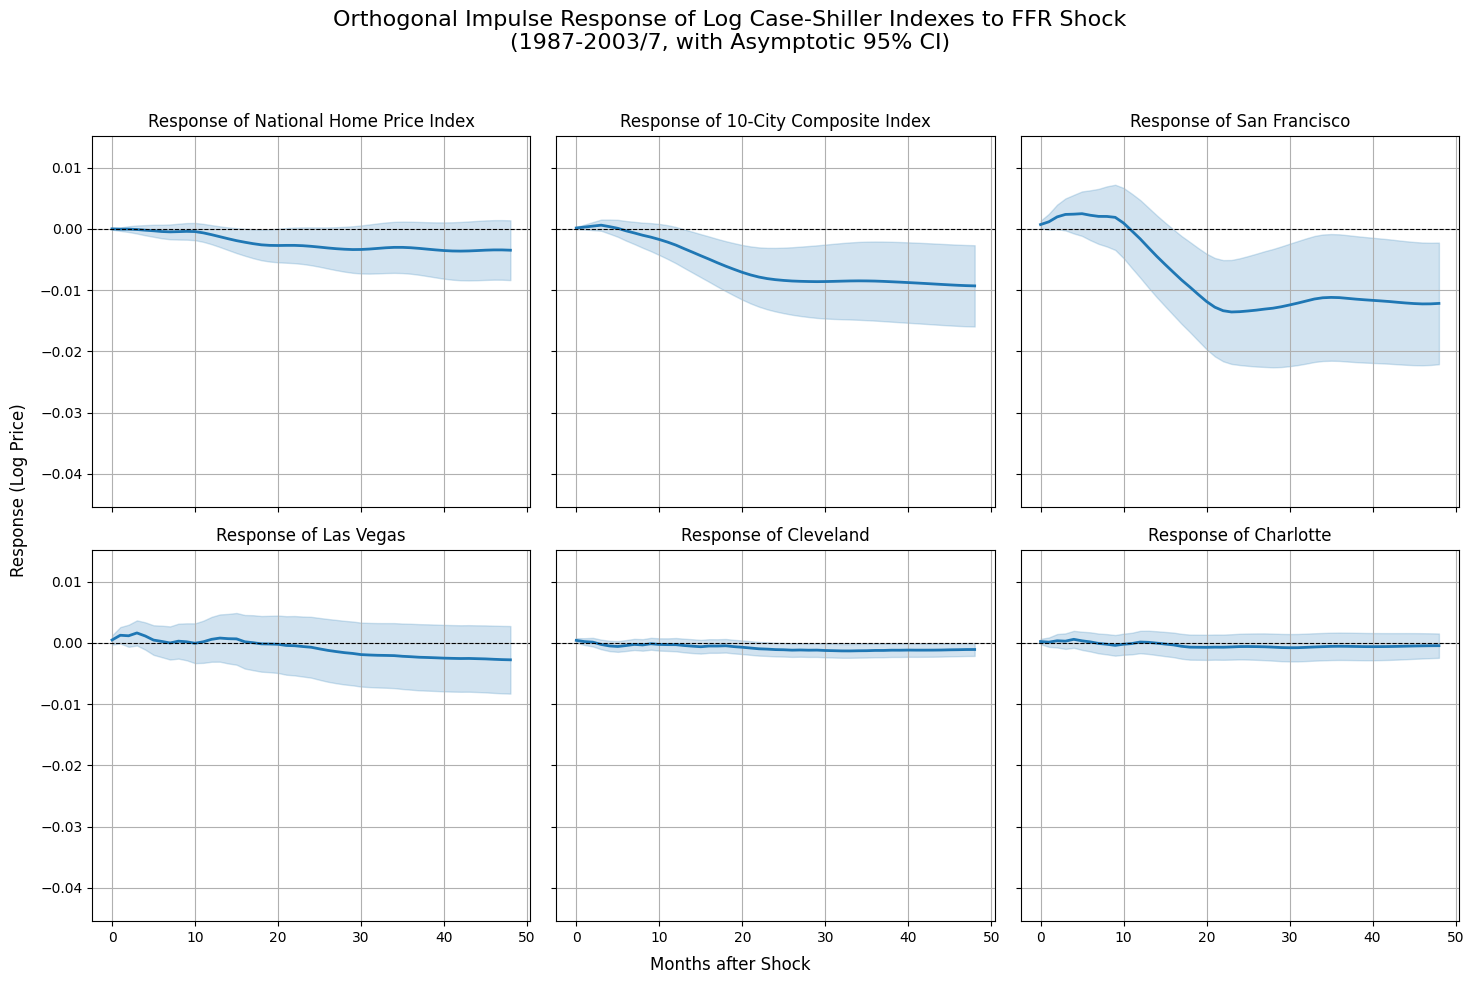

In [18]:
# --- Plot Results ---
plot_irf_grid(
    irf_results_sub, 
    cs_names, 
    title_suffix="(1987-2003/7, with Asymptotic 95% CI)",
    ylim=(y_min_full, y_max_full) # Use limits from full period
)